In [1]:
# Air Quality Analysis and Prediction Using Machine Learning

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")
print("Air Quality ML Project is ready to begin.")

Libraries imported successfully!
Air Quality ML Project is ready to begin.


In [2]:
#Set the project folder

from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\ASUS\Desktop\Air_Quality_ML_Project")

# Check whether the folder exists
print("Project folder exists:", PROJECT_DIR.exists())

# List the files in the project folder
print("\nFiles in project folder:")
for file in PROJECT_DIR.iterdir():
    print(file.name)

Project folder exists: True

Files in project folder:
.git
.gitignore
AirQualityUCI.csv
AirQualityUCI.xlsx
air_quality_output
app.py
README.md
requirements.txt


In [3]:
#Load the original dataset

file_path = PROJECT_DIR / "AirQualityUCI.xlsx"

df_raw = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df_raw.shape)

print("\nFirst 5 rows:")
display(df_raw.head())

Dataset loaded successfully!
Dataset shape: (9357, 15)

First 5 rows:


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2004-03-10,18:00:00,2.6,1360.00,150,11.881723,1045.50,166.0,1056.25,113.0,1692.00,1267.50,13.60,48.875001,0.757754
1,2004-03-10,19:00:00,2.0,1292.25,112,9.397165,954.75,103.0,1173.75,92.0,1558.75,972.25,13.30,47.700000,0.725487
2,2004-03-10,20:00:00,2.2,1402.00,88,8.997817,939.25,131.0,1140.00,114.0,1554.50,1074.00,11.90,53.975000,0.750239
3,2004-03-10,21:00:00,2.2,1375.50,80,9.228796,948.25,172.0,1092.00,122.0,1583.75,1203.25,11.00,60.000000,0.786713
4,2004-03-10,22:00:00,1.6,1272.25,51,6.518224,835.50,131.0,1205.00,116.0,1490.00,1110.00,11.15,59.575001,0.788794


In [4]:
#Understand the dataset structure

print("Dataset dimensions:")
print(df_raw.shape)

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nMissing values in each column:")
print(df_raw.isnull().sum())
#Check special missing-value markers

print("Checking -200 values in each column:\n")

print((df_raw == -200).sum())

print("\nTotal number of -200 values:")
print((df_raw == -200).sum().sum())

Dataset dimensions:
(9357, 15)

Column names:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   datetime64[ns]
 1   Time           9357 non-null   object        
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   int64         
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null

In [5]:
#Check how many rows have a valid CO target

valid_target_rows = (df_raw["CO(GT)"] != -200).sum()

missing_target_rows = (df_raw["CO(GT)"] == -200).sum()

print("Original number of rows:", len(df_raw))
print("Rows with valid CO(GT):", valid_target_rows)
print("Rows with missing CO(GT):", missing_target_rows)
print(
    "Percentage of rows with valid CO(GT):",
    round(valid_target_rows / len(df_raw) * 100, 2),
    "%"
)

Original number of rows: 9357
Rows with valid CO(GT): 7674
Rows with missing CO(GT): 1683
Percentage of rows with valid CO(GT): 82.01 %


In [6]:
#Select features for the initial ML model

target = "CO(GT)"

features = [
    "PT08.S1(CO)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
    "T",
    "RH",
    "AH"
]

# Create a working copy with the selected columns
df_model = df_raw[[target] + features].copy()

# Convert -200 markers to proper missing values
df_model = df_model.replace(-200, np.nan)

print("Original dataset rows:", len(df_raw))

print("Rows with valid CO target:",
      df_model[target].notna().sum())

print("\nMissing values in selected columns:")
print(df_model.isnull().sum())

print("\nRows with valid CO and all selected features:",
      df_model.dropna().shape[0])

Original dataset rows: 9357
Rows with valid CO target: 7674

Missing values in selected columns:
CO(GT)         1683
PT08.S1(CO)     366
C6H6(GT)        366
NOx(GT)        1639
NO2(GT)        1642
T               366
RH              366
AH              366
dtype: int64

Rows with valid CO and all selected features: 6941


In [7]:
df_model_clean = df_model.dropna(subset=[target]).copy()

# Separate predictors and target
X = df_model_clean[features]
y = df_model_clean[target]

print("Original dataset rows:", len(df_raw))
print("Rows with valid target:", len(df_model_clean))
print("Predictor columns:", len(features))
print("Missing target values:", y.isna().sum())
print("Missing predictor values:", X.isna().sum().sum())
print("\nPrepared dataset preview:")
display(df_model_clean.head())

Original dataset rows: 9357
Rows with valid target: 7674
Predictor columns: 7
Missing target values: 0
Missing predictor values: 2479

Prepared dataset preview:


,CO(GT),PT08.S1(CO),C6H6(GT),NOx(GT),NO2(GT),T,RH,AH
0,2.6,1360.00,11.881723,166.0,113.0,13.60,48.875001,0.757754
1,2.0,1292.25,9.397165,103.0,92.0,13.30,47.700000,0.725487
2,2.2,1402.00,8.997817,131.0,114.0,11.90,53.975000,0.750239
3,2.2,1375.50,9.228796,172.0,122.0,11.00,60.000000,0.786713
4,1.6,1272.25,6.518224,131.0,116.0,11.15,59.575001,0.788794


In [8]:
# Analyse missing predictor values

missing_summary = pd.DataFrame({
    "Missing Values": X.isnull().sum(),
    "Missing Percentage": (X.isnull().mean() * 100).round(2)
})

print("Missing-value summary:")
display(missing_summary)

print("\nTotal rows available for modelling:", len(X))
print("Total predictor columns:", X.shape[1])

Missing-value summary:


,Missing Values,Missing Percentage
PT08.S1(CO),330,4.30
C6H6(GT),330,4.30
NOx(GT),413,5.38
NO2(GT),416,5.42
T,330,4.30
RH,330,4.30
AH,330,4.30



Total rows available for modelling: 7674
Total predictor columns: 7


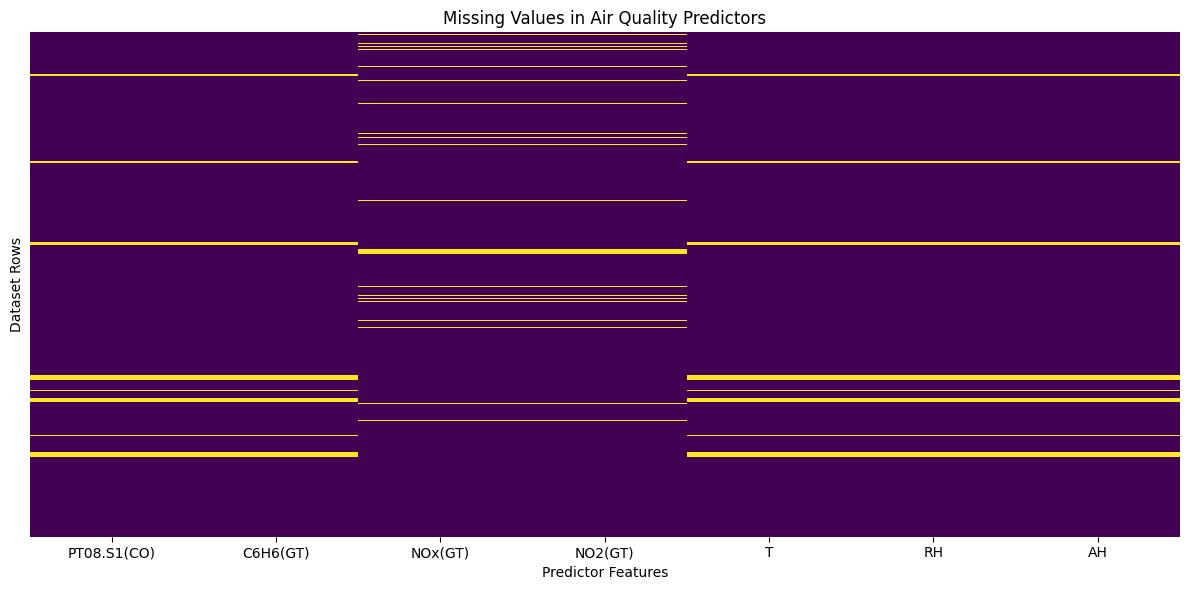

In [9]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    X.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values in Air Quality Predictors")
plt.xlabel("Predictor Features")
plt.ylabel("Dataset Rows")
plt.tight_layout()
plt.show()

Statistical Summary of CO(GT):


,CO(GT)
count,7674.000000
mean,2.152750
std,1.453252
min,0.100000
25%,1.100000
50%,1.800000
75%,2.900000
max,11.900000



Skewness of CO(GT): 1.37
Median CO(GT): 1.8
Mean CO(GT): 2.153


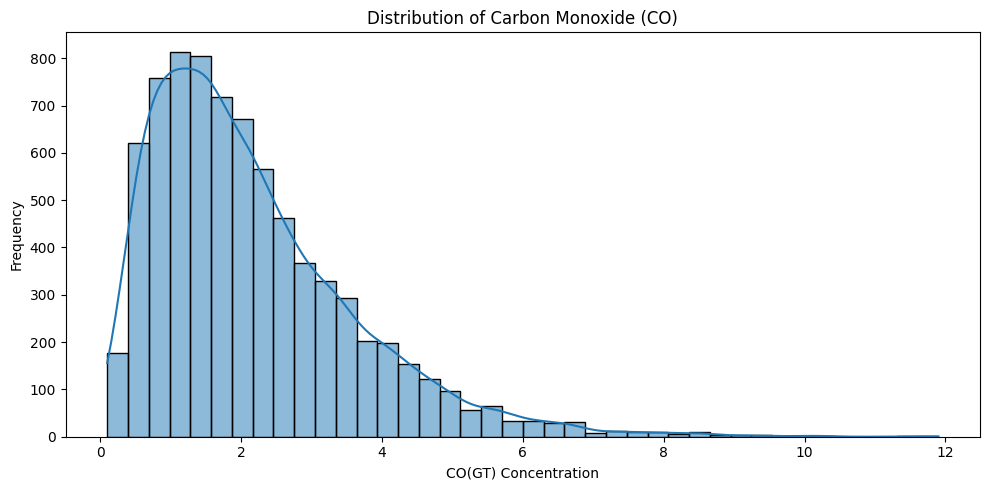

In [10]:
# Statistical analysis of CO(GT)

print("Statistical Summary of CO(GT):")
display(y.describe().to_frame())

print("\nSkewness of CO(GT):", round(y.skew(), 3))
print("Median CO(GT):", round(y.median(), 3))
print("Mean CO(GT):", round(y.mean(), 3))

# Plot the distribution
plt.figure(figsize=(10, 5))

sns.histplot(y, bins=40, kde=True)

plt.title("Distribution of Carbon Monoxide (CO)")
plt.xlabel("CO(GT) Concentration")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


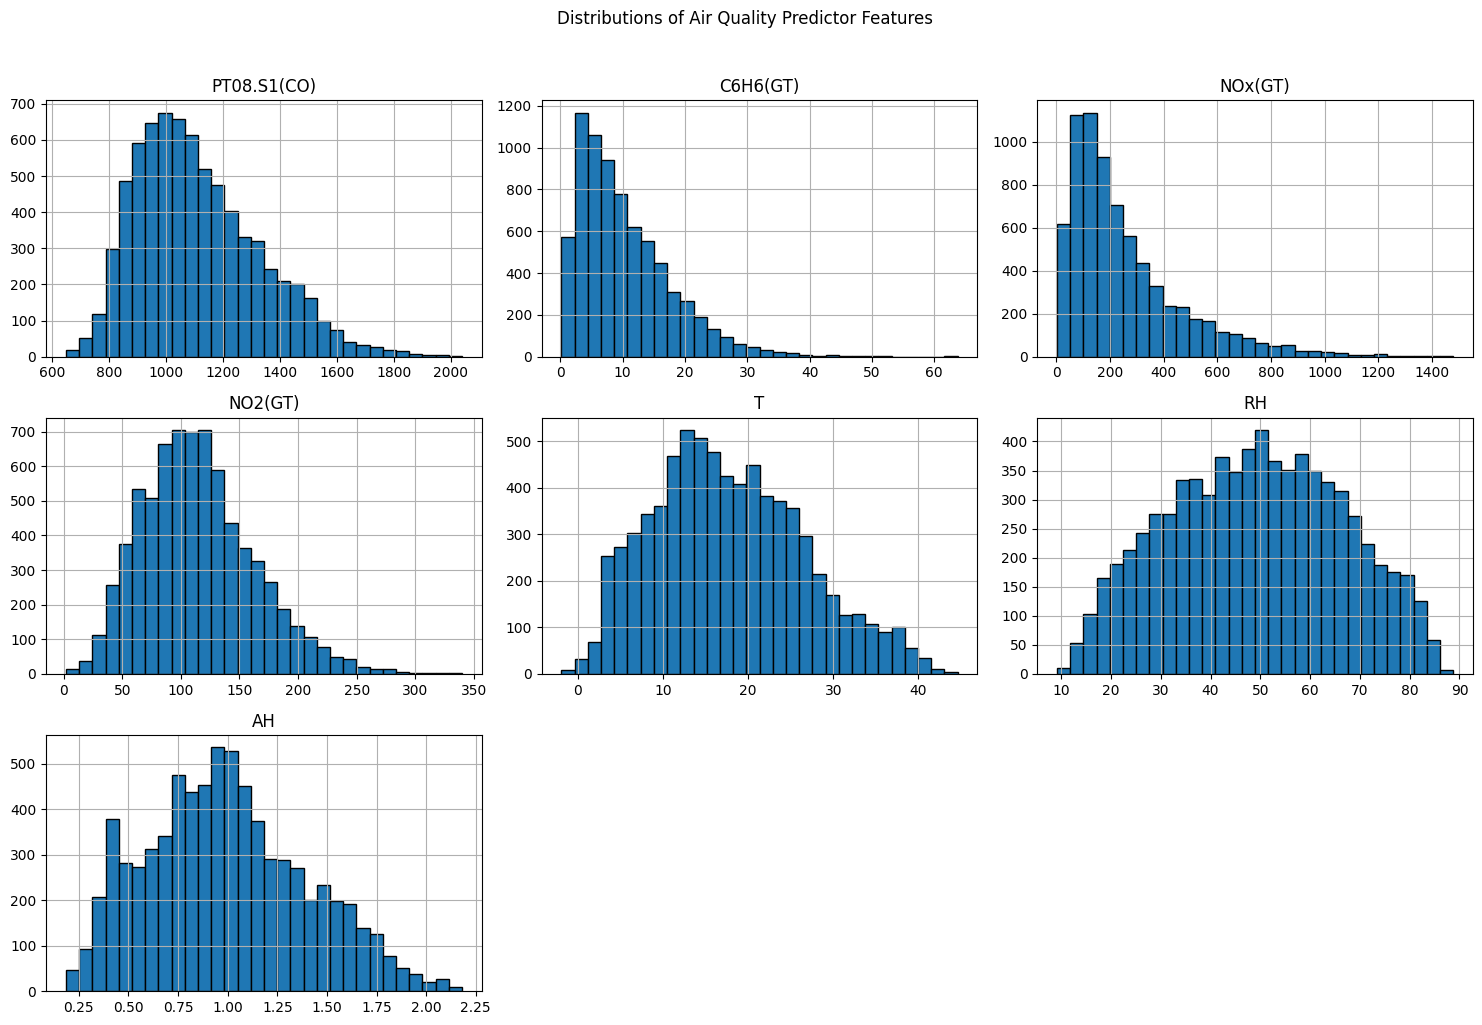

In [11]:
# Distribution of predictor features

features = [
    "PT08.S1(CO)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
    "T",
    "RH",
    "AH"
]

X[features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distributions of Air Quality Predictor Features", y=1.02)
plt.tight_layout()
plt.show()


Correlation of each predictor with CO(GT):


,Correlation
C6H6(GT),0.931091
PT08.S1(CO),0.879292
NOx(GT),0.795054
NO2(GT),0.683533
RH,0.048896
AH,0.048555
T,0.022113


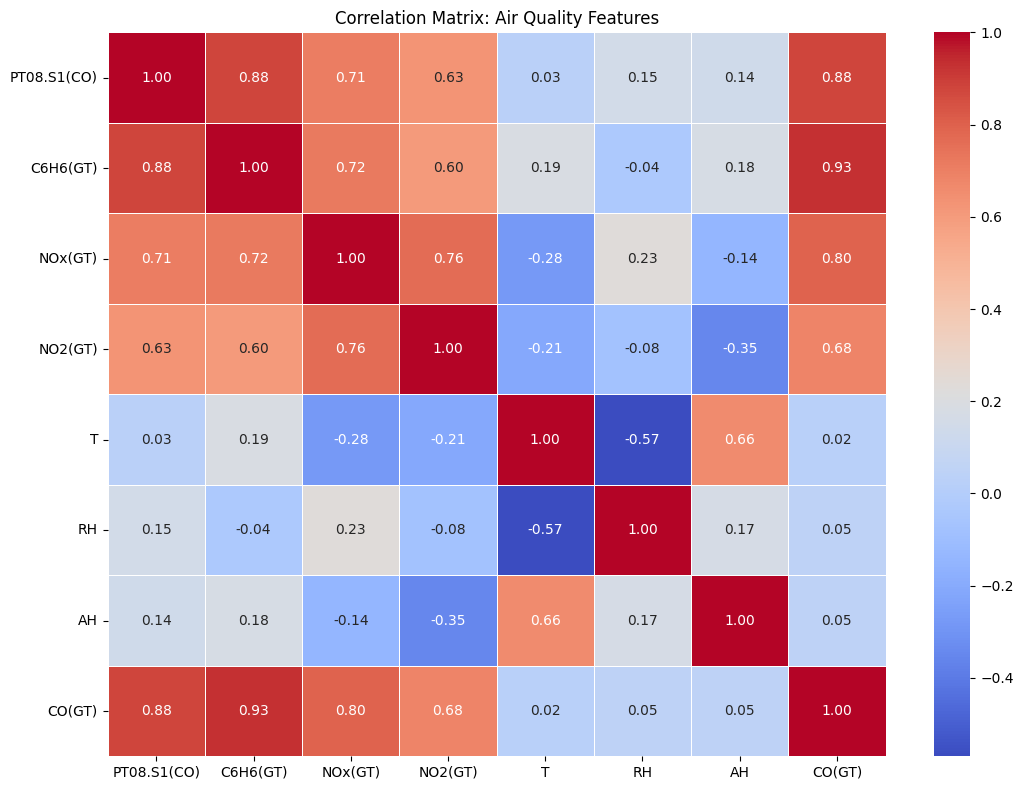

In [12]:
# Correlation analysis

# Combine predictors and target for correlation analysis
correlation_data = pd.concat([X, y], axis=1)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr(numeric_only=True)

# Display correlation of each feature with CO(GT)
co_correlation = correlation_matrix["CO(GT)"].drop("CO(GT)")
co_correlation = co_correlation.sort_values(ascending=False)

print("Correlation of each predictor with CO(GT):")
display(co_correlation.to_frame(name="Correlation"))

# Plot the correlation matrix
plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Matrix: Air Quality Features")
plt.tight_layout()
plt.show()

In [13]:
# Prepare data for machine learning

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create an imputer that learns medians from training data
imputer = SimpleImputer(strategy="median")

# Fit only on training data, then transform both sets
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=features,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=features,
    index=X_test.index
)

print("DATA PREPARATION SUMMARY")
print("-" * 40)
print("Original dataset rows:", len(df_raw))
print("Rows with valid CO target:", len(df_model_clean))
print("Training rows:", len(X_train_imputed))
print("Testing rows:", len(X_test_imputed))
print("Number of predictor features:", len(features))
print("Missing values in training predictors:",
      X_train_imputed.isnull().sum().sum())
print("Missing values in testing predictors:",
      X_test_imputed.isnull().sum().sum())
print("Missing values in training target:", y_train.isnull().sum())
print("Missing values in testing target:", y_test.isnull().sum())

DATA PREPARATION SUMMARY
----------------------------------------
Original dataset rows: 9357
Rows with valid CO target: 7674
Training rows: 6139
Testing rows: 1535
Number of predictor features: 7
Missing values in training predictors: 0
Missing values in testing predictors: 0
Missing values in training target: 0
Missing values in testing target: 0


LINEAR REGRESSION - MODEL EVALUATION
---------------------------------------------
Mean Absolute Error (MAE): 0.3143
Mean Squared Error (MSE):  0.2575
Root Mean Squared Error (RMSE): 0.5075
R-squared (R²): 0.8764
R-squared (%): 87.64%

Actual vs Predicted CO (first 10 test observations):


,Actual CO,Predicted CO
0,7.1,3.773398
1,0.9,1.027102
2,3.8,3.438199
3,2.3,2.107975
4,0.9,0.952293
5,2.2,2.821638
6,5.6,3.862181
7,1.6,1.621983
8,3.1,2.745222
9,3.3,2.977438


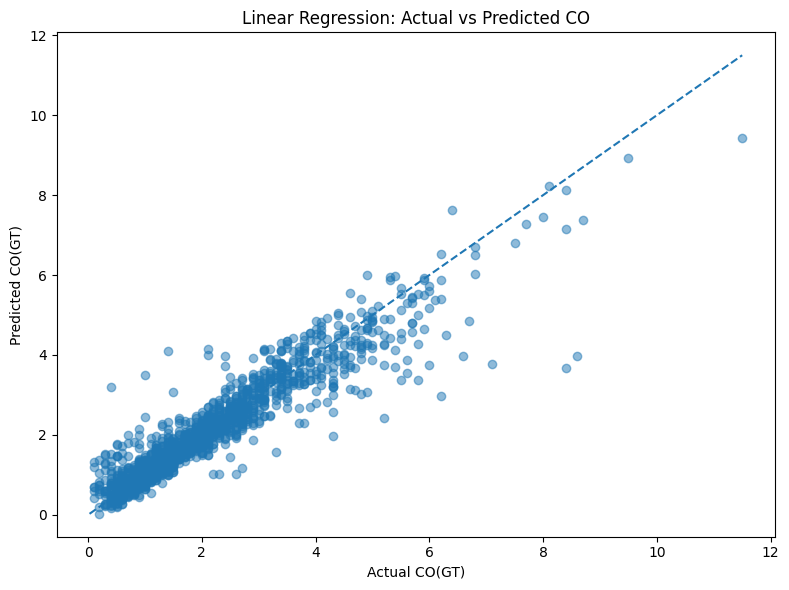

In [14]:
# Train and evaluate Linear Regression

# Create and train the model
lr_model = LinearRegression()
lr_model.fit(X_train_imputed, y_train)

# Make predictions on the test data
y_pred_lr = lr_model.predict(X_test_imputed)

# Calculate evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Display results
print("LINEAR REGRESSION - MODEL EVALUATION")
print("-" * 45)
print(f"Mean Absolute Error (MAE): {mae_lr:.4f}")
print(f"Mean Squared Error (MSE):  {mse_lr:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lr:.4f}")
print(f"R-squared (R²): {r2_lr:.4f}")
print(f"R-squared (%): {r2_lr * 100:.2f}%")

# Compare actual and predicted CO values
comparison_df = pd.DataFrame({
    "Actual CO": y_test.values,
    "Predicted CO": y_pred_lr
})

print("\nActual vs Predicted CO (first 10 test observations):")
display(comparison_df.head(10))

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_lr, alpha=0.5)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred_lr.min())
max_value = max(y_test.max(), y_pred_lr.max())
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual CO(GT)")
plt.ylabel("Predicted CO(GT)")
plt.title("Linear Regression: Actual vs Predicted CO")
plt.tight_layout()
plt.show()

DECISION TREE REGRESSION - MODEL EVALUATION
---------------------------------------------
MAE:  0.2975
MSE:  0.2053
RMSE: 0.4531
R²:   0.9014
R² (%): 90.14%


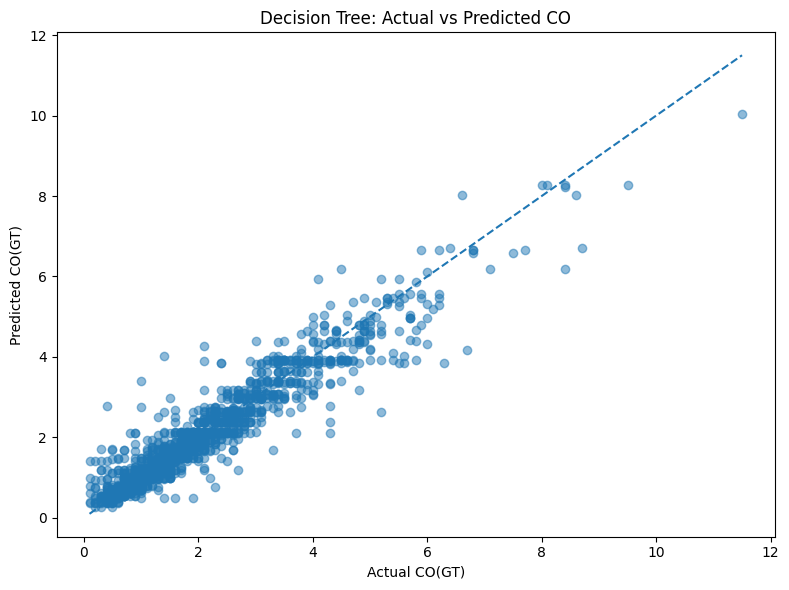

In [15]:
# Decision Tree Regression

# Create and train the model
dt_model = DecisionTreeRegressor(
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train_imputed, y_train)

# Predict on the test set
y_pred_dt = dt_model.predict(X_test_imputed)

# Evaluate performance
mae_dt = mean_absolute_error(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("DECISION TREE REGRESSION - MODEL EVALUATION")
print("-" * 45)
print(f"MAE:  {mae_dt:.4f}")
print(f"MSE:  {mse_dt:.4f}")
print(f"RMSE: {rmse_dt:.4f}")
print(f"R²:   {r2_dt:.4f}")
print(f"R² (%): {r2_dt * 100:.2f}%")

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_dt, alpha=0.5)

min_value = min(y_test.min(), y_pred_dt.min())
max_value = max(y_test.max(), y_pred_dt.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual CO(GT)")
plt.ylabel("Predicted CO(GT)")
plt.title("Decision Tree: Actual vs Predicted CO")
plt.tight_layout()
plt.show()

In [16]:
# Train and evaluate Random Forest Regression

# Initialize the model
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_imputed, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_imputed)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, y_pred_rf)

# Display results
print("RANDOM FOREST REGRESSION - MODEL EVALUATION")
print("-" * 50)
print(f"MAE:  {rf_mae:.4f}")
print(f"MSE:  {rf_mse:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"R²:   {rf_r2:.4f}")
print(f"R² (%): {rf_r2 * 100:.2f}%")

RANDOM FOREST REGRESSION - MODEL EVALUATION
--------------------------------------------------
MAE:  0.2545
MSE:  0.1613
RMSE: 0.4016
R²:   0.9226
R² (%): 92.26%


In [17]:
from sklearn.ensemble import GradientBoostingRegressor

# Train Gradient Boosting
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_imputed, y_train)

# Predict on test data
gb_predictions = gb_model.predict(X_test_imputed)

# Evaluate
gb_mae = mean_absolute_error(y_test, gb_predictions)
gb_mse = mean_squared_error(y_test, gb_predictions)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test, gb_predictions)

print("GRADIENT BOOSTING REGRESSION - MODEL EVALUATION")
print("-" * 50)
print(f"MAE:    {gb_mae:.4f}")
print(f"MSE:    {gb_mse:.4f}")
print(f"RMSE:   {gb_rmse:.4f}")
print(f"R²:     {gb_r2:.4f}")
print(f"R² (%): {gb_r2 * 100:.2f}%")

GRADIENT BOOSTING REGRESSION - MODEL EVALUATION
--------------------------------------------------
MAE:    0.2713
MSE:    0.1797
RMSE:   0.4239
R²:     0.9137
R² (%): 91.37%


In [18]:
from sklearn.ensemble import ExtraTreesRegressor

et_model = ExtraTreesRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train_imputed, y_train)

et_predictions = et_model.predict(X_test_imputed)

et_mae = mean_absolute_error(y_test, et_predictions)
et_rmse = np.sqrt(mean_squared_error(y_test, et_predictions))
et_r2 = r2_score(y_test, et_predictions)

print("Extra Trees Results")
print("MAE:", round(et_mae, 4))
print("RMSE:", round(et_rmse, 4))
print("R² Score:", round(et_r2, 4))

Extra Trees Results
MAE: 0.2521
RMSE: 0.4017
R² Score: 0.9225


In [19]:
model_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mae_lr,
        "RMSE": rmse_lr,
        "R² Score": r2_lr
    },
    {
        "Model": "Decision Tree",
        "MAE": mae_dt,
        "RMSE": rmse_dt,
        "R² Score": r2_dt
    },
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R² Score": rf_r2
    },
    {
        "Model": "Gradient Boosting",
        "MAE": gb_mae,
        "RMSE": gb_rmse,
        "R² Score": gb_r2
    },
    {
        "Model": "Extra Trees",
        "MAE": et_mae,
        "RMSE": et_rmse,
        "R² Score": et_r2
    }
])

model_comparison = model_comparison.sort_values(
    by="R² Score",
    ascending=False
).reset_index(drop=True)

display(model_comparison.round(4))

,Model,MAE,RMSE,R² Score
0,Random Forest,0.2545,0.4016,0.9226
1,Extra Trees,0.2521,0.4017,0.9225
2,Gradient Boosting,0.2713,0.4239,0.9137
3,Decision Tree,0.2975,0.4531,0.9014
4,Linear Regression,0.3143,0.5075,0.8764


,Importance
C6H6(GT),0.8170
NOx(GT),0.0896
PT08.S1(CO),0.0295
NO2(GT),0.0243
T,0.0186
AH,0.0108
RH,0.0102


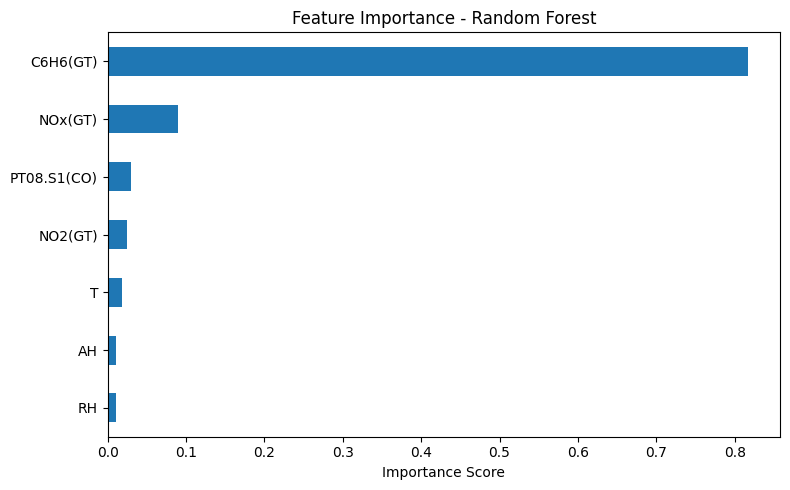

In [20]:

# Identify the most important features
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values(ascending=False)

display(importance.to_frame("Importance").round(4))

# Visualize feature importance
importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

In [21]:
import json
import joblib

# Create a folder for the project files
os.makedirs("air_quality_output", exist_ok=True)

# Save the best model
joblib.dump(rf_model, "air_quality_output/random_split_random_forest_baseline.pkl")

# Save feature names
with open("air_quality_output/feature_metadata.json", "w") as f:
    json.dump({"features": features, "target": "CO(GT)"}, f, indent=4)

# Save model evaluation results
model_comparison.to_json(
    "air_quality_output/model_metrics.json",
    orient="records",
    indent=4
)

print("Model and metadata saved successfully!")
print("Files:", os.listdir("air_quality_output"))

Model and metadata saved successfully!
Files: ['best_air_quality_model.pkl', 'chronological_extra_trees_baseline.pkl', 'feature_metadata.json', 'feature_names.pkl', 'model_metrics.json', 'random_split_random_forest_baseline.pkl']


In [22]:
df_raw["DateTime"] = pd.to_datetime(
    df_raw["Date"].astype(str) + " " + df_raw["Time"].astype(str),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

print(df_raw[["Date", "Time", "DateTime"]].head())
print("\nMissing datetime values:", df_raw["DateTime"].isna().sum())

        Date      Time            DateTime
0 2004-03-10  18:00:00 2004-03-10 18:00:00
1 2004-03-10  19:00:00 2004-03-10 19:00:00
2 2004-03-10  20:00:00 2004-03-10 20:00:00
3 2004-03-10  21:00:00 2004-03-10 21:00:00
4 2004-03-10  22:00:00 2004-03-10 22:00:00

Missing datetime values: 0


In [23]:
# Sort observations chronologically
df_chrono = df_raw.sort_values("DateTime").copy()

# Reset row index
df_chrono = df_chrono.reset_index(drop=True)

# Check the date range
print("Earliest observation:", df_chrono["DateTime"].min())
print("Latest observation:", df_chrono["DateTime"].max())

# Display first and last observations
display(df_chrono[["DateTime", "CO(GT)"]].head())
display(df_chrono[["DateTime", "CO(GT)"]].tail())

Earliest observation: 2004-03-10 18:00:00
Latest observation: 2005-04-04 14:00:00


,DateTime,CO(GT)
0,2004-03-10 18:00:00,2.6
1,2004-03-10 19:00:00,2.0
2,2004-03-10 20:00:00,2.2
3,2004-03-10 21:00:00,2.2
4,2004-03-10 22:00:00,1.6


,DateTime,CO(GT)
9352,2005-04-04 10:00:00,3.1
9353,2005-04-04 11:00:00,2.4
9354,2005-04-04 12:00:00,2.4
9355,2005-04-04 13:00:00,2.1
9356,2005-04-04 14:00:00,2.2


In [24]:
# Remove rows where the CO target is the missing-value marker
df_chrono_clean = df_chrono[
    df_chrono["CO(GT)"].notna() &
    (df_chrono["CO(GT)"] != -200)
].copy()
# Replace missing markers in predictor columns
df_chrono_clean[features] = (
    df_chrono_clean[features].replace(-200, np.nan)
)
# Select predictors and target
X_chrono = df_chrono_clean[features]
y_chrono = df_chrono_clean["CO(GT)"]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(df_chrono_clean) * 0.8)

X_train_chrono = X_chrono.iloc[:split_index]
X_test_chrono = X_chrono.iloc[split_index:]

y_train_chrono = y_chrono.iloc[:split_index]
y_test_chrono = y_chrono.iloc[split_index:]

print("Training rows:", len(X_train_chrono))
print("Testing rows:", len(X_test_chrono))
print("Training CO mean:", round(y_train_chrono.mean(), 2))
print("Testing CO mean:", round(y_test_chrono.mean(), 2))
print("Training CO minimum:", y_train_chrono.min())
print("Testing CO minimum:", y_test_chrono.min())

Training rows: 6139
Testing rows: 1535
Training CO mean: 2.19
Testing CO mean: 2.0
Training CO minimum: 0.1
Testing CO minimum: 0.1


In [25]:

# Create an imputer and fit it only on training data
chrono_imputer = SimpleImputer(strategy="median")

X_train_chrono_imputed = chrono_imputer.fit_transform(X_train_chrono)
X_test_chrono_imputed = chrono_imputer.transform(X_test_chrono)

print("Missing values in training:", 
      __import__("numpy").isnan(X_train_chrono_imputed).sum())

print("Missing values in testing:", 
      __import__("numpy").isnan(X_test_chrono_imputed).sum())

print("Training shape:", X_train_chrono_imputed.shape)
print("Testing shape:", X_test_chrono_imputed.shape)

Missing values in training: 0
Missing values in testing: 0
Training shape: (6139, 7)
Testing shape: (1535, 7)


In [26]:
# Train Random Forest on corrected chronological data
rf_chrono_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_chrono_model.fit(X_train_chrono_imputed, y_train_chrono)

# Predict on the later observations
chrono_predictions = rf_chrono_model.predict(X_test_chrono_imputed)

# Evaluate performance
chrono_mae = mean_absolute_error(y_test_chrono, chrono_predictions)
chrono_rmse = np.sqrt(mean_squared_error(y_test_chrono, chrono_predictions))
chrono_r2 = r2_score(y_test_chrono, chrono_predictions)

print("CHRONOLOGICAL RANDOM FOREST RESULTS")
print("-" * 40)
print("MAE:", round(chrono_mae, 4))
print("RMSE:", round(chrono_rmse, 4))
print("R² Score:", round(chrono_r2, 4))
print("R² (%):", round(chrono_r2 * 100, 2), "%")

CHRONOLOGICAL RANDOM FOREST RESULTS
----------------------------------------
MAE: 0.386
RMSE: 0.5668
R² Score: 0.8223
R² (%): 82.23 %


In [27]:
evaluation_comparison = pd.DataFrame([
    {
        "Evaluation": "Random Split",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2 Score": rf_r2
    },
    {
        "Evaluation": "Chronological Split",
        "MAE": chrono_mae,
        "RMSE": chrono_rmse,
        "R2 Score": chrono_r2
    }
])

display(evaluation_comparison.round(4))

,Evaluation,MAE,RMSE,R2 Score
0,Random Split,0.2545,0.4016,0.9226
1,Chronological Split,0.3860,0.5668,0.8223


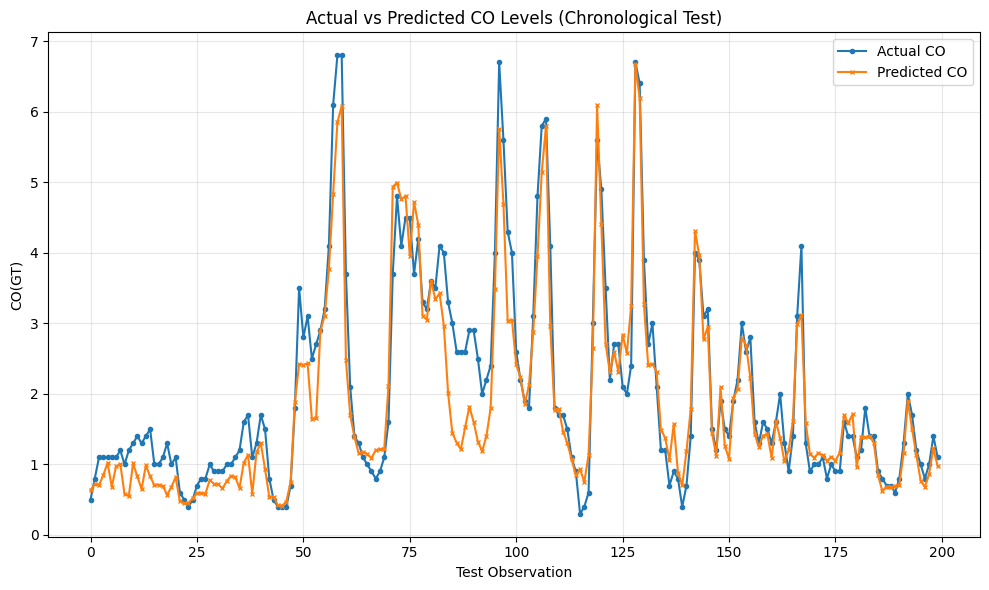

In [28]:
plt.figure(figsize=(10, 6))

plt.plot(
    y_test_chrono.values[:200],
    label="Actual CO",
    marker="o",
    markersize=3
)

plt.plot(
    chrono_predictions[:200],
    label="Predicted CO",
    marker="x",
    markersize=3
)

plt.title("Actual vs Predicted CO Levels (Chronological Test)")
plt.xlabel("Test Observation")
plt.ylabel("CO(GT)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

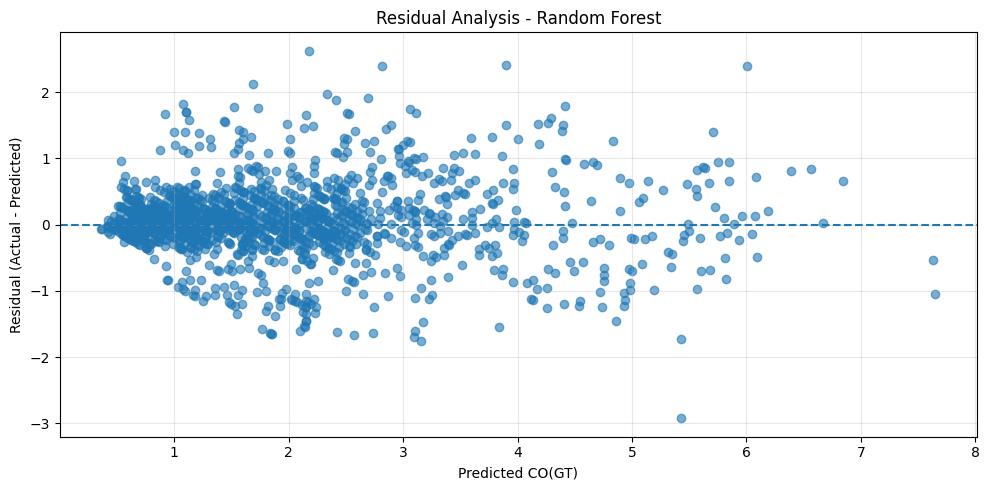

In [29]:
residuals = y_test_chrono.values - chrono_predictions

plt.figure(figsize=(10, 5))
plt.scatter(chrono_predictions, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Analysis - Random Forest")
plt.xlabel("Predicted CO(GT)")
plt.ylabel("Residual (Actual - Predicted)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [30]:
from sklearn.ensemble import ExtraTreesRegressor
# Train Extra Trees on chronological training data
extra_trees_chrono = ExtraTreesRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

extra_trees_chrono.fit(X_train_chrono_imputed, y_train_chrono)

# Predict on chronological test data
extra_trees_predictions = extra_trees_chrono.predict(X_test_chrono_imputed)

# Evaluate performance
extra_mae = mean_absolute_error(y_test_chrono, extra_trees_predictions)
extra_rmse = np.sqrt(mean_squared_error(y_test_chrono, extra_trees_predictions))
extra_r2 = r2_score(y_test_chrono, extra_trees_predictions)

print("CHRONOLOGICAL EXTRA TREES RESULTS")
print("-" * 40)
print("MAE:", round(extra_mae, 4))
print("RMSE:", round(extra_rmse, 4))
print("R² Score:", round(extra_r2, 4))
print("R² (%):", round(extra_r2 * 100, 2), "%")

CHRONOLOGICAL EXTRA TREES RESULTS
----------------------------------------
MAE: 0.3694
RMSE: 0.5453
R² Score: 0.8355
R² (%): 83.55 %


In [31]:
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
# Define all 5 models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

results = []

# Train and evaluate each model chronologically
for name, model in models.items():
    model.fit(X_train_chrono_imputed, y_train_chrono)

    predictions = model.predict(X_test_chrono_imputed)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_chrono, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_chrono, predictions)),
        "R2 Score": r2_score(y_test_chrono, predictions)
    })

chronological_results = pd.DataFrame(results)

display(chronological_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.3605,0.5521,0.8314
1,Decision Tree,0.5628,0.8429,0.6069
2,Random Forest,0.3860,0.5668,0.8223
3,Extra Trees,0.3694,0.5453,0.8355
4,Gradient Boosting,0.3619,0.5363,0.8409


In [32]:
# Identify the best model based on chronological R² score
best_model_row = chronological_results.loc[
    chronological_results["R2 Score"].idxmax()
]

print("Best Model:", best_model_row["Model"])
print("MAE:", round(best_model_row["MAE"], 4))
print("RMSE:", round(best_model_row["RMSE"], 4))
print("R² Score:", round(best_model_row["R2 Score"], 4))

Best Model: Gradient Boosting
MAE: 0.3619
RMSE: 0.5363
R² Score: 0.8409


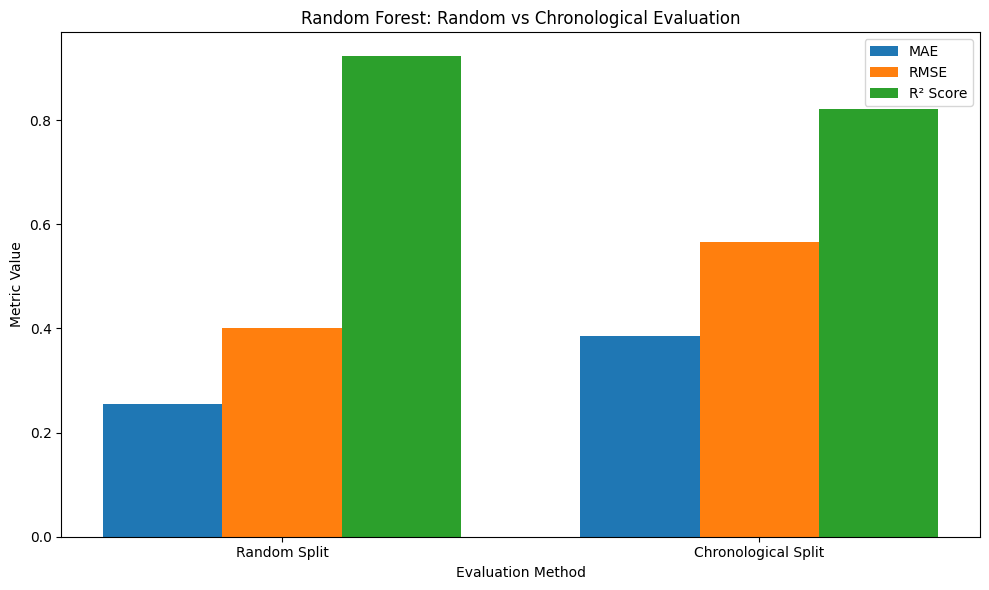

In [33]:
evaluation_names = ["Random Split", "Chronological Split"]
mae_values = [rf_mae, chrono_mae]
rmse_values = [rf_rmse, chrono_rmse]
r2_values = [rf_r2, chrono_r2]

x = np.arange(len(evaluation_names))
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(x - width, mae_values, width, label="MAE")
plt.bar(x, rmse_values, width, label="RMSE")
plt.bar(x + width, r2_values, width, label="R² Score")

plt.title("Random Forest: Random vs Chronological Evaluation")
plt.xlabel("Evaluation Method")
plt.ylabel("Metric Value")
plt.xticks(x, evaluation_names)
plt.legend()
plt.tight_layout()
plt.show()

In [34]:
import joblib
# Create output folder
os.makedirs("air_quality_output", exist_ok=True)

# Save the best chronological model
joblib.dump(extra_trees_chrono, "air_quality_output/chronological_extra_trees_baseline.pkl")

# Save the feature names
joblib.dump(features, "air_quality_output/feature_names.pkl")

print("Best model saved successfully!")
print("Model: Extra Trees")
print("R² Score:", round(best_model_row["R2 Score"], 4))

Best model saved successfully!
Model: Extra Trees
R² Score: 0.8409


In [35]:
folder = "air_quality_output"

print("Files saved:")
for file in os.listdir(folder):
    print("-", file)

Files saved:
- best_air_quality_model.pkl
- chronological_extra_trees_baseline.pkl
- feature_metadata.json
- feature_names.pkl
- model_metrics.json
- random_split_random_forest_baseline.pkl


# Advanced Model Experimentation

## Comparative Evaluation of Regression Algorithms

This section introduces additional regression algorithms and
evaluates all models using a chronological train-test split.

The objective is to compare model performance while preserving
the temporal order of observations.

In [36]:
# Advanced Model Experimentation
# Prepare data independently without changing the existing workflow

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load original dataset independently
PROJECT_DIR = Path(r"C:\Users\ASUS\Desktop\Air_Quality_ML_Project")

data = pd.read_excel(PROJECT_DIR / "AirQualityUCI.xlsx")

# Prepare datetime
data["DateTime"] = pd.to_datetime(
    data["Date"].astype(str) + " " + data["Time"].astype(str),
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# Sort observations chronologically
data = data.sort_values("DateTime").copy()

# Define predictors and target
advanced_features = [
    "PT08.S1(CO)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
    "T",
    "RH",
    "AH"
]

advanced_target = "CO(GT)"

# Convert missing-value markers into NaN
data[advanced_features + [advanced_target]] = (
    data[advanced_features + [advanced_target]]
    .replace(-200, np.nan)
)

# Keep observations with a valid target
data = data.dropna(subset=[advanced_target])

X_advanced = data[advanced_features]
y_advanced = data[advanced_target]

# Chronological 80:20 split
split_index = int(len(data) * 0.80)

X_train_advanced = X_advanced.iloc[:split_index]
X_test_advanced = X_advanced.iloc[split_index:]

y_train_advanced = y_advanced.iloc[:split_index]
y_test_advanced = y_advanced.iloc[split_index:]

print("ADVANCED MODEL DATA PREPARATION")
print("-" * 45)
print("Total observations:", len(data))
print("Training observations:", len(X_train_advanced))
print("Testing observations:", len(X_test_advanced))
print("Features:", len(advanced_features))
print("Missing target values:", y_advanced.isna().sum())

print("\nTraining period:")
print(data["DateTime"].iloc[0], "to",
      data["DateTime"].iloc[split_index - 1])

print("\nTesting period:")
print(data["DateTime"].iloc[split_index], "to",
      data["DateTime"].iloc[-1])

ADVANCED MODEL DATA PREPARATION
---------------------------------------------
Total observations: 7674
Training observations: 6139
Testing observations: 1535
Features: 7
Missing target values: 0

Training period:
2004-03-10 18:00:00 to 2005-01-29 06:00:00

Testing period:
2005-01-29 07:00:00 to 2005-04-04 14:00:00


In [37]:
# Train and Compare Regression Models

models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", LinearRegression())
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=100, random_state=42, n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingRegressor(random_state=42))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesRegressor(
            n_estimators=100, random_state=42, n_jobs=-1
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ]),

    "SVR": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf"))
    ])
}

results = []
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train_advanced, y_train_advanced)

    predictions = model.predict(X_test_advanced)

    results.append({
        "Model": name,
        "R2": r2_score(y_test_advanced, predictions),
        "MAE": mean_absolute_error(y_test_advanced, predictions),
        "RMSE": np.sqrt(mean_squared_error(
            y_test_advanced, predictions
        ))
    })

    trained_models[name] = model

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

print("\nMODEL COMPARISON RESULTS")
display(comparison_df.round(4))

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting
Training: Extra Trees
Training: KNN
Training: SVR

MODEL COMPARISON RESULTS


,Model,R2,MAE,RMSE
0,SVR,0.8525,0.3427,0.5164
1,Gradient Boosting,0.8409,0.3619,0.5363
2,Extra Trees,0.8355,0.3694,0.5453
3,Linear Regression,0.8314,0.3605,0.5521
4,Random Forest,0.8223,0.3860,0.5668
5,KNN,0.7576,0.4743,0.6619
6,Decision Tree,0.6069,0.5628,0.8429


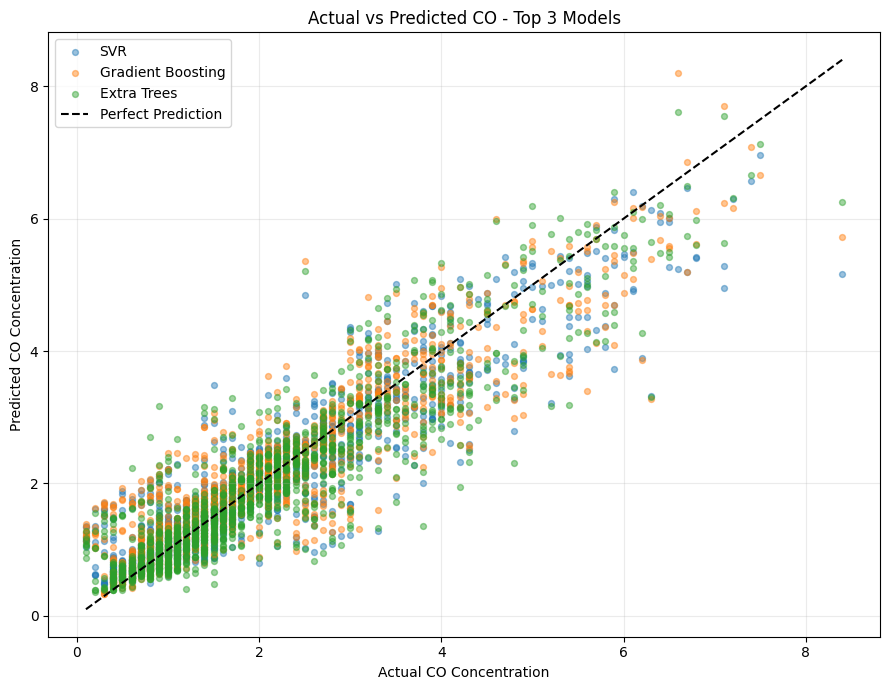

In [38]:
# Actual vs Predicted comparison for top 3 models

import matplotlib.pyplot as plt

top_models = comparison_df.head(3)["Model"].tolist()

plt.figure(figsize=(9, 7))

for name in top_models:
    predictions = trained_models[name].predict(X_test_advanced)

    plt.scatter(
        y_test_advanced,
        predictions,
        alpha=0.45,
        s=18,
        label=name
    )

# Perfect prediction reference line
minimum = float(np.min(y_test_advanced))
maximum = float(np.max(y_test_advanced))

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "k--",
    label="Perfect Prediction"
)

plt.xlabel("Actual CO Concentration")
plt.ylabel("Predicted CO Concentration")
plt.title("Actual vs Predicted CO - Top 3 Models")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

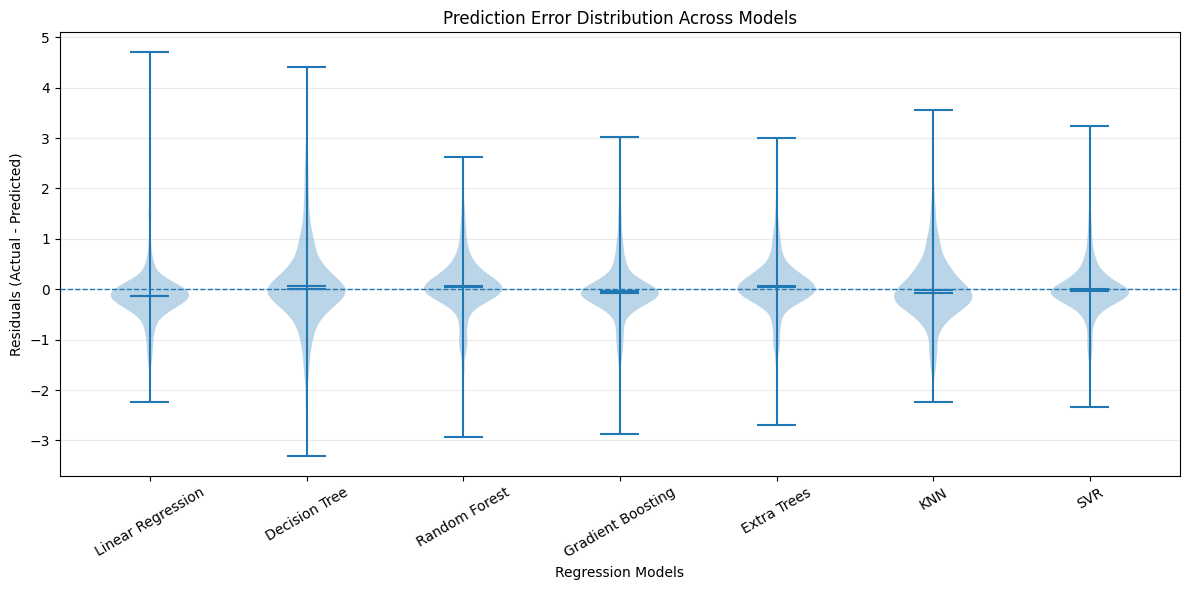

In [39]:
# Residual distribution comparison

residual_data = []

for name, model in trained_models.items():
    predictions = model.predict(X_test_advanced)

    residuals = y_test_advanced - predictions

    residual_data.append(residuals.to_numpy())

plt.figure(figsize=(12, 6))

plt.violinplot(
    residual_data,
    showmedians=True,
    showmeans=True
)

plt.xticks(
    range(1, len(trained_models) + 1),
    list(trained_models.keys()),
    rotation=30
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Prediction Error Distribution Across Models")
plt.xlabel("Regression Models")
plt.ylabel("Residuals (Actual - Predicted)")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [40]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate

# chronological validation folds
tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

for name, model in models.items():

    print("Validating:", name)

    scores = cross_validate(
        model,
        X_train_advanced,
        y_train_advanced,
        cv=tscv,
        scoring={
            "R2": "r2",
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean R2": scores["test_R2"].mean(),
        "Mean MAE": -scores["test_MAE"].mean(),
        "Mean RMSE": -scores["test_RMSE"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

display(cv_comparison.sort_values("Mean RMSE").round(4))

Validating: Linear Regression
Validating: Decision Tree
Validating: Random Forest
Validating: Gradient Boosting
Validating: Extra Trees
Validating: KNN
Validating: SVR


,Model,Mean R2,Mean MAE,Mean RMSE
4,Extra Trees,0.8613,0.3515,0.5182
2,Random Forest,0.8632,0.3586,0.5188
3,Gradient Boosting,0.8375,0.3774,0.5510
0,Linear Regression,0.8464,0.3666,0.5533
5,KNN,0.8252,0.4184,0.5898
1,Decision Tree,0.7863,0.4591,0.6519
6,SVR,0.7454,0.4509,0.7270


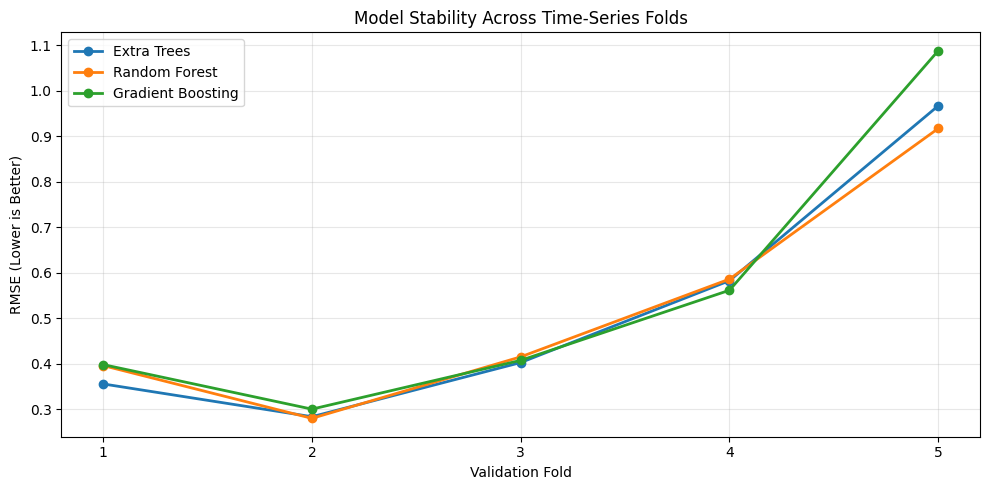

In [41]:
# Fold-wise performance stability

top_three = ["Extra Trees", "Random Forest", "Gradient Boosting"]

fold_results = {}

for name in top_three:
    scores = cross_validate(
        models[name],
        X_train_advanced,
        y_train_advanced,
        cv=tscv,
        scoring="neg_root_mean_squared_error"
    )

    fold_results[name] = -scores["test_score"]

plt.figure(figsize=(10, 5))

for name, values in fold_results.items():
    plt.plot(
        range(1, 6),
        values,
        marker="o",
        linewidth=2,
        label=name
    )

plt.title("Model Stability Across Time-Series Folds")
plt.xlabel("Validation Fold")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
from sklearn.model_selection import RandomizedSearchCV

# Avoid nested parallel processing
models["Extra Trees"].named_steps["model"].set_params(n_jobs=1)
models["Random Forest"].named_steps["model"].set_params(n_jobs=1)

param_grids = {
    "Extra Trees": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    }
}

tuned_models = {}

for name in param_grids:

    print("Tuning:", name)

    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=param_grids[name],
        n_iter=15,
        cv=tscv,
        scoring="neg_root_mean_squared_error",
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train_advanced, y_train_advanced)

    tuned_models[name] = search.best_estimator_

    print("Best CV RMSE:", round(-search.best_score_, 4))
    print("Best parameters:", search.best_params_)
    print("-" * 50)

Tuning: Extra Trees
Best CV RMSE: 0.5107
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_depth': None}
--------------------------------------------------
Tuning: Random Forest
Best CV RMSE: 0.5148
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 20}
--------------------------------------------------


In [43]:
# Evaluate tuned models on chronological test data

tuned_test_results = []

for name, model in tuned_models.items():

    predictions = model.predict(X_test_advanced)

    tuned_test_results.append({
        "Model": name,
        "R2": r2_score(y_test_advanced, predictions),
        "MAE": mean_absolute_error(y_test_advanced, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_advanced, predictions)
        )
    })

tuned_test_df = pd.DataFrame(tuned_test_results)

display(tuned_test_df.round(4))

,Model,R2,MAE,RMSE
0,Extra Trees,0.8517,0.3448,0.5178
1,Random Forest,0.8352,0.3722,0.5458


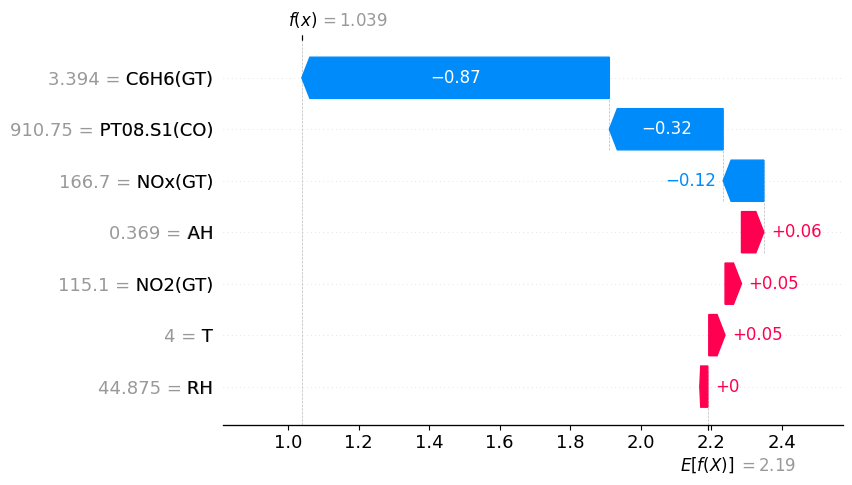

In [44]:
import shap

# Select tuned Extra Trees model
best_model = tuned_models["Extra Trees"]

# Extract trained preprocessing and model
imputer = best_model.named_steps["imputer"]
extra_trees = best_model.named_steps["model"]

# Transform test data
X_test_imputed = imputer.transform(X_test_advanced)

# Create SHAP explainer
explainer = shap.TreeExplainer(extra_trees)

# Select one test observation
sample_index = 10

shap_values = explainer(
    X_test_imputed[sample_index:sample_index + 1]
)

# Add feature names
shap_values.feature_names = advanced_features

# Display waterfall visualization
shap.plots.waterfall(
    shap_values[0],
    max_display=7
)

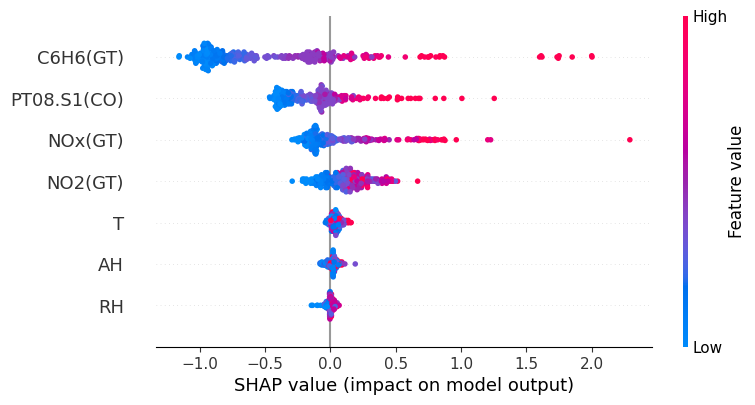

In [45]:
# SHAP global feature explanation

X_sample = X_test_imputed[:300]

shap_sample = explainer(X_sample)

shap_sample.feature_names = advanced_features

shap.plots.beeswarm(
    shap_sample,
    max_display=7
)

In [46]:
import joblib
import json
from pathlib import Path

# Existing project output folder
output_dir = PROJECT_DIR / "air_quality_output"
output_dir.mkdir(exist_ok=True)

# Select tuned Extra Trees
final_model = tuned_models["Extra Trees"]

# Save as a NEW file (do not overwrite existing model)
joblib.dump(
    final_model,
    output_dir / "tuned_extra_trees_model.pkl"
)

# Save feature names separately
joblib.dump(
    advanced_features,
    output_dir / "tuned_feature_names.pkl"
)

# Save evaluation metrics
final_metrics = {
    "model": "Tuned Extra Trees Regressor",
    "test_r2": float(tuned_test_df.loc[
        tuned_test_df["Model"] == "Extra Trees", "R2"
    ].iloc[0]),
    "test_mae": float(tuned_test_df.loc[
        tuned_test_df["Model"] == "Extra Trees", "MAE"
    ].iloc[0]),
    "test_rmse": float(tuned_test_df.loc[
        tuned_test_df["Model"] == "Extra Trees", "RMSE"
    ].iloc[0])
}

with open(output_dir / "tuned_model_metrics.json", "w") as f:
    json.dump(final_metrics, f, indent=4)

print("Tuned model saved successfully!")
print(final_metrics)

Tuned model saved successfully!
{'model': 'Tuned Extra Trees Regressor', 'test_r2': 0.8516700026647813, 'test_mae': 0.3447797635693535, 'test_rmse': 0.5178226825307115}


In [47]:
print("Saved files:")

for file in output_dir.iterdir():
    print("-", file.name)

Saved files:
- best_air_quality_model.pkl
- feature_metadata.json
- feature_names.pkl
- model_metrics.json
- tuned_extra_trees_model.pkl
- tuned_feature_names.pkl
- tuned_model_metrics.json
